# World models: acting and imagining in one loop

An environment in Dew is two pure functions over a pytree: `reset(key)` starts an episode and
`step(state, action)` advances it, each answering a `TimeStep`. That is the shape of every JAX-native
simulator, and it is also the shape of a learned world model, whose state is a latent and whose step
is a network. So acting in a simulator and imagining in a world model are the same loop,
`env_rollout`: a `lax.scan` of a policy and a step.

This tutorial runs that loop three ways on MuJoCo Playground's `CartpoleBalance`: a random policy, a
PPO agent trained in the simulator, and a DreamerV3 agent that learns a world model from its replay and
trains its actor and critic inside it. Then comes Dreamer 4's world model at a small scale, trained by
shortcut forcing on video. It ends with first-person drone racing: its physics a JAX environment
a privileged teacher learns to fly, its camera drawn by a ray tracer outside JAX.

## Setup

In [ ]:
%pip install -q "dewml[cuda13,playground,hyperlux] @ git+https://github.com/AshishKumar4/dew@f56bbd29356b6458885693cbcc335654cf1166c0" --extra-index-url https://pypi.dewml.dev/simple

In [1]:
import time

import jax
import jax.numpy as jnp
import numpy as np
import optax

from dew import figures
from dew.rl.env import env_rollout, start
from dew.rl.playground import Playground, playground

TASK = "CartpoleBalance"
probe = Playground.load(TASK)
print(jax.devices()[0], "observation", probe.env.observation_size, "action", probe.action_size)

cuda:0 observation 5 action 1


## The loop

`playground(TASK, count)` is `count` copies of the task stepped together, each episode cut after
1000 steps as Playground trains them. A policy is `policy(params, observation, key, memory)`; a
random one ignores everything but its key.

In [2]:
env = playground(TASK, 256)

def random_policy(params, observation, key, memory):
    action = jax.random.uniform(key, (observation.shape[0], env.action_size), minval=-1, maxval=1)
    return action, {}, memory

rolled = jax.jit(lambda carry: env_rollout(env, random_policy, None, carry, 1000))
_, steps = rolled(start(env, jax.random.key(0)))
returns = np.asarray(steps.following.reward.sum(0))
print(f"random policy: mean return {returns.mean():.1f} over {len(returns)} episodes")

random policy: mean return 358.9 over 256 episodes


## PPO in the simulator

`ControlPPOObjective` is Brax's PPO: a tanh-squashed normal policy and a value network, the clipped
surrogate over advantages computed from the live critic. `ControlRollout` collects with the live policy
and serves each collection as several passes of minibatches, one an update.

In [3]:
import itertools

from dew.data.dataset import Loader
from dew.objectives.rl.control import ActorCritic, ControlPPOObjective, ControlRollout, episode_return
from dew.training import Trainer

objective = ControlPPOObjective(ActorCritic(probe.action_size), int(probe.env.observation_size),
                                discount=0.995, reward_scaling=10.0, entropy_cost=1e-2)
rollout = ControlRollout(objective, playground(TASK, 2048), unroll_length=30, unrolls=16, epochs=16,
                         minibatches=32)
idle = Loader(train=lambda partition: itertools.repeat({"step": np.zeros((1,), np.float32)}), val=None,
              records=1, batch=1)
began = time.perf_counter()
ppo = Trainer(objective, optax.adam(1e-3), key=jax.random.key(1), rollout=rollout).fit(idle, steps=8 * 512,
                                                                                        log_every=512)
print(f"{time.perf_counter() - began:.0f} s; greedy return",
      episode_return(objective, playground(TASK, 64), ppo.variables, jax.random.key(2), 1000))

╭─  dew · ActorCritic  ───────────────────────────────────────────────────────────────────────────────────────────╮
│ 268,387 parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 1  ·  float32              │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  4096/4096  100%  237.1 step/s  0:00:25 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                     0.2480  █▇██▇▇▄▁     ↓ 1,352×                                                        │
│   entropy                 0.08654  ████▇▇▅▁        ↓ 86%                                                        │
│   pg_clipfrac              0.1693  ▄▁▅▁█▁▇▇       ↑ 138%                                                        │
│   policy                 -0.05414  ▇█▆█▁▇▅▁       ↓ 314%                                                        │
│   ppo_kl                  0.08489  ▃▂▄▂▆▁██       ↑ 319%                                                        │
│   value                    0.3030  █▇██▇▇▄▁     ↓ 1,107×                                                        │
│   data_wait_ms            0.01468  ▃█▇▃▁▃▂▁       ↓ 2.3%                                                        │
│   grad_norm                 175.8  █▇▇▆▇▇▃▁        ↓ 15×                                                        │
│   pg_clipfrac_lower 0   flops 6.532e+10   compiles 1.000   cache_hits 763.0   cache_misses 0   peak_memory_gib  │
│ 0.3772                                                                                                          │
│ throughput                                                                                                      │
│   step_time_ms              3.514  ▂█▃▂▃▃▃▁       ↓ 7.4%                                                        │
│   samples_per_sec         291,411  ▇▁▆▇▆▆▆█       ↑ 8.0%                                                        │
│   mfu                        3.7%  ▇▁▆▇▆▆▆█     ↑ 0.3 pt                                                        │
│   hlo_flops_util             3.7%  ▇▁▆▇▆▆▆█     ↑ 0.3 pt                                                        │
│   hfu                        3.7%  ▇▁▆▇▆▆▆█     ↑ 0.3 pt                                                        │
│   rollout_seconds           1.868  █▄▂▂▁▁▁▂        ↓ 73%                                                        │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
│ rollout                                                                                                         │
│   episode_return              nan  ▁▂█                                                                          │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ ActorCritic  ───────────────────────────╮
│    trained  4096 steps in 0:00:25           │
│ first step  after 6.25 s                    │
│       then  217.9 step/s                    │
│    goodput  75.0% of the wall time in steps │
│ final loss  0.2480                          │
╰─────────────────────────────────────────────╯

25 s; greedy return 999.743896484375


## DreamerV3: a world model as an environment

`DreamerV3Objective` learns an RSSM from replayed windows: a block GRU's deterministic state and
categorical latents, decoders for the observation, reward and continuation. The world model is an
`Env` (`LatentEnv`): its state is the latent and its step the prior, so the actor and critic train on
`env_rollout` over it, from every replayed state.

In [4]:
from dew.objectives.rl.dreamer import DreamerRollout, DreamerV3Objective, WorldModel, episodes_return

sys_env = playground(TASK, 16)
dreamer = DreamerV3Objective(WorldModel(int(probe.env.observation_size), probe.action_size))
replay = DreamerRollout(dreamer, sys_env, capacity=4000, batch=16, length=64, train_ratio=1024.0, prefill=64)
began = time.perf_counter()
agent = Trainer(dreamer, optax.adam(1e-4), key=jax.random.key(3), rollout=replay).fit(idle, steps=20_000,
                                                                                       log_every=2000)
print(f"{time.perf_counter() - began:.0f} s, {replay.environment_steps} environment steps; return",
      episodes_return(dreamer, playground(TASK, 16), agent.variables, jax.random.key(4), 1000))

╭─  dew · WorldModel  ────────────────────────────────────────────────────────────────────────────────────────────╮
│ 637,446 parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 1  ·  float32              │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  20000/20000  100%  45.7 step/s  0:07:42 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                        3.426  █▃▂▁▁▁▁▁▁▁        ↓ 62%                                                    │
│   imagined_return             188.9  ▁▄▅▆▆▆▇▇██        ↑ 11×                                                    │
│   loss_continue             0.02044  █▂▁▁▁▁▁▁▁▁       ↓ 0.9%                                                    │
│   loss_decoder              0.01257  ▇▅█▄▄▅▄▂▂▁        ↓ 76%                                                    │
│   loss_dynamics               1.378  ▁▁▇██▆█▇▆▆       ↑ 9.6%                                                    │
│   loss_policy             -0.005012  █▄▁▁▁▁▁▁▁▁       ↓ 101%                                                    │
│   loss_replay_value           1.153  █▄▃▂▁▂▂▂▂▂        ↓ 80%                                                    │
│   loss_representation         1.378  ▁▁▇██▆█▇▆▆       ↑ 9.6%                                                    │
│   loss_reward                0.5121  █▅▄▃▃▁▂▂▁▂        ↓ 32%                                                    │
│   loss_value                  1.024  █▄▃▁▁▁▁▂▁▁        ↓ 76%                                                    │
│   return_scale                109.0  ▁▂▄▅▆▆▇▇██        ↑ 17×                                                    │
│   data_wait_ms              0.01742  ▂▅▆▃▁▄▆▆▃█        ↑ 11%                                                    │
│   grad_norm                   4.267  █▆▅▄▂▁▁▁▁▁        ↓ 62%                                                    │
│   flops 3.288e+10   compiles 1.000   cache_hits 1,349   cache_misses 45.00   peak_memory_gib 1.348              │
│ throughput                                                                                                      │
│   step_time_ms                21.51  █▂▂▁▂▁▂▂▁▃       ↓ 7.8%                                                    │
│   samples_per_sec             743.7  ▁▇▇█▇█▇▇█▆       ↑ 8.4%                                                    │
│   mfu                          0.3%  ▁▇▇█▇█▇▇█▆            →                                                    │
│   hlo_flops_util               0.3%  ▁▇▇█▇█▇▇█▆            →                                                    │
│   hfu                          0.3%  ▁▇▇█▇█▇▇█▆            →                                                    │
│   rollout_seconds             35.44  █▁▁▁▁▁▁▁▁▁        ↓ 33%                                                    │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
│ rollout                                                                                                         │
│   episode_return                nan                                                                             │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ WorldModel  ────────────────────────────╮
│    trained  20000 steps in 0:07:43          │
│ first step  after 33.25 s                   │
│       then  46.6 step/s                     │
│    goodput  92.8% of the wall time in steps │
│ final loss  3.426                           │
╰─────────────────────────────────────────────╯

463 s, 21024 environment steps; return 574.3026733398438


## Imagining

Start from replayed posterior states and let the world model run on under the agent's policy. The
imagined rewards are what the critic learns from; compare them with what the replay actually earned.

In [5]:
from dew.objectives.rl.dreamer import LatentEnv
from dew.rl.distributions import twohot_bins
from dew.rl.env import Carry

windows = replay.sample(jax.random.key(5))
model = dreamer.model.bind(agent.variables, rngs={"latent": jax.random.key(6)})
deter, stoch = model.initial((16,))
first = jnp.asarray(windows["first"]).at[:, 0].set(True)
previous = jnp.concatenate([jnp.zeros_like(windows["action"][:, :1]), windows["action"][:, :-1]], 1)
for t in range(32):
    deter, stoch, _ = dreamer.observe(model, deter, stoch, windows["observation"][:, t], previous[:, t], first[:, t])
world = LatentEnv(dreamer.model, agent.variables, twohot_bins())
state, feature = world.at(deter, stoch, jax.random.key(7))

def imagined_policy(params, feature, key, memory):
    mean, std = dreamer.model.apply(params, feature, method=WorldModel.policy)
    return jnp.clip(mean + std * jax.random.normal(key, mean.shape), -1, 1), {}, None

_, dream = env_rollout(world, imagined_policy, agent.variables, Carry(state, feature, jax.random.key(8)), 32,
                       reset=False)
figures.curve({"replayed": np.asarray(windows["reward"][:, 32:]).mean(0),
               "imagined": np.asarray(dream.following.reward).mean(1)}, x_label="step", y_label="reward")

Figure(460 x 290, 20 shapes)

## Dreamer 4's world model at a small scale

Dreamer 4 replaces the RSSM with a causal tokenizer and a transformer over its latents, trained by
shortcut forcing: each frame gets its own signal level and step size, and a large step learns to match
two of its own half steps, so four steps generate what diffusion forcing needs many for. Here it learns
bouncing-ball video and predicts eight frames from four.

╭─  dew · CausalTokenizer  ───────────────────────────────────────────────────────────────────────────────────────╮
│ 1.6M parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 32  ·  float32                │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2000/2000  100%  60.1 step/s  0:00:45 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                   0.1464  ▁█       ↑ 0.2%                                                                │
│   mse                    0.1464  ▁█       ↑ 0.2%                                                                │
│   data_wait_ms          0.01571  █▁       ↓ 6.3%                                                                │
│   grad_norm              0.4125  █▁        ↓ 34%                                                                │
│   compiles                1.000  ▁▁            →                                                                │
│   cache_hits              1,380  ▁▁            →                                                                │
│   cache_misses            218.0  ▁▁            →                                                                │
│   peak_memory_gib         2.535  ▁█            →                                                                │
│ throughput                                                                                                      │
│   step_time_ms            15.89  █▁       ↓ 1.0%                                                                │
│   samples_per_sec         2,013  ▁█       ↑ 1.0%                                                                │
│   hlo_flops_util           3.9%  ▁█            →                                                                │
│   hfu                      3.9%  ▁█            →                                                                │
│ optimizer                                                                                                       │
│   accepted               100.0%  ▁▁            →                                                                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ CausalTokenizer  ───────────────────────╮
│    trained  2000 steps in 0:00:52           │
│ first step  after 20.12 s                   │
│       then  62.9 step/s                     │
│    goodput  61.2% of the wall time in steps │
│ final loss  0.1464                          │
╰─────────────────────────────────────────────╯

╭─  dew · Dynamics  ──────────────────────────────────────────────────────────────────────────────────────────────╮
│ 6.3M parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 32  ·  float32                │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3000/3000  100%  74.2 step/s  0:01:01 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                  0.01171  █▂▁        ↓ 82%                                                               │
│   frame_loss            0.01171  █▂▁        ↓ 82%                                                               │
│   data_wait_ms          0.01588  ▁█▆       ↑ 9.0%                                                               │
│   grad_norm              0.9765  █▃▁        ↓ 84%                                                               │
│   compiles 1.000   cache_hits 1,380   cache_misses 220.0   peak_memory_gib 2.535                                │
│ throughput                                                                                                      │
│   step_time_ms            13.68  █▄▁       ↓ 2.9%                                                               │
│   samples_per_sec         2,339  ▁▅█       ↑ 3.0%                                                               │
│   hlo_flops_util           7.8%  ▁▅█     ↑ 0.2 pt                                                               │
│   hfu                      7.8%  ▁▅█     ↑ 0.2 pt                                                               │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ Dynamics  ──────────────────────────────╮
│    trained  3000 steps in 0:01:08           │
│ first step  after 26.63 s                   │
│       then  72.4 step/s                     │
│    goodput  60.9% of the wall time in steps │
│ final loss  0.01171                         │
╰─────────────────────────────────────────────╯

Figure(527.2 x 120, 3 shapes)
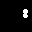
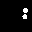
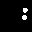
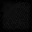
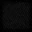
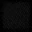
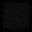
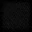
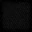
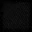
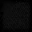

In [6]:
def bouncing(rows, frames, size, seed):
    """Videos [rows, frames, size, size, 1] in [-1, 1] of two balls bouncing off the walls."""
    rng = np.random.default_rng(seed)
    grid = np.stack(np.meshgrid(np.arange(size), np.arange(size), indexing="ij"), -1) + 0.5
    videos = np.full((rows, frames, size, size, 1), -1.0, np.float32)
    for video in videos:
        position, velocity = rng.uniform(3, size - 3, (2, 2)), rng.uniform(-1.5, 1.5, (2, 2))
        for frame in video:
            for ball in range(2):
                frame[np.sum(np.square(grid - position[ball]), -1) <= 2.5 ** 2, 0] = 1.0
            position = position + velocity
            velocity = np.where((position < 2.5) | (position > size - 2.5), -velocity, velocity)
            position = np.clip(position, 2.5, size - 2.5)
    return videos


from dew.objectives.world_model import CausalTokenizer, Dynamics, TokenizerObjective, WorldModelObjective

videos, held = bouncing(2048, 12, 32, 0), bouncing(8, 12, 32, 1)
clips = Loader(train=lambda partition: ({"video": videos[i:i + 32]} for i in itertools.cycle(range(0, 2048, 32))),
               val=None, records=2048, batch=32)
tokenizer = CausalTokenizer((32, 32, 1), width=128, depth=3, latents=16, bottleneck=8)
tokens = Trainer(TokenizerObjective(tokenizer), optax.adam(3e-4), key=jax.random.key(9)).fit(clips, steps=2000,
                                                                                            log_every=1000)
dynamics = Dynamics(latents=16, bottleneck=8, spatial=16, width=256, depth=6, frames=12)
world_model = WorldModelObjective(dynamics, tokenizer, tokens.variables)
trained = Trainer(world_model, optax.adam(3e-4), key=jax.random.key(10)).fit(clips, steps=3000, log_every=1000)
latents = world_model.latents(jnp.asarray(held))
predicted = world_model.generate(trained.variables, latents[:, :4], 8, jax.random.key(11), steps=4)
frames = np.asarray(tokenizer.apply(tokens.variables, predicted, method=CausalTokenizer.decode))
def pixels(video):
    return np.repeat(np.round((np.clip(video, -1, 1) + 1) * 127.5).astype(np.uint8), 3, -1)

figures.images([np.concatenate([pixels(held[0, 4:]), pixels(frames[0])])], columns=8, size=52,
               rows=["truth", "imagined"])

## First-person gate racing: physics in JAX, a camera outside it

`dew.rl.flight` races first-person drones through gates. Its physics is JAX's (`dew.rl.quadrotor`: a
racing quadrotor's rotors, motor lag, drag, ground effect and battery sag), so one drone's race is an
`Env`, `FlightEnv`, and thousands fly inside one jitted rollout. Each episode flies a course of its own,
a loop or a chain of gate primitives with pillars among the gates, and starts anywhere on it; each drone
is randomized as a real one would be (thrust, rate limits, latency, camera tilt).

A camera is drawn outside JAX: `GateRace` steps the same races and has a renderer draw each drone's
view, here HyperLux's ray tracer over a few CC0 assets that `tools/fpv_assets.py` downloads. That makes
it a `Simulator`, stepped from the host a batch at a time. The policy sees the camera alone, the next
gate lit. The drone's state, the next gates' corners and the obstacles are privileged: a teacher reads
them, and a world model learns to predict them.

{
 "license": "CC0 (polyhaven.com/license) textures; geometry Dew's",
 "ground": [
  "ground_aerial_grass_rock.glb",
  "ground_forrest_ground_01.glb",
  "ground_aerial_asphalt_01.glb",
  "ground_aerial_beach_01.glb",
  "ground_rocky_terrain_02.glb",
  "ground_brown_mud_leaves_01.glb"
 ],
 "sky": [
  "sky_kloofendal_48d_partly_cloudy_puresky.glb",
  "sky_lilienstein.glb",
  "sky_the_sky_is_on_fire.glb",
  "sky_kloppenheim_02.glb"
 ],
 "gate": [
  "gate_orange.glb",
  "gate_blue.glb",
  "gate_white.glb",
  "gate_padded.glb"
 ],
 "lit": [
  "lit_green.glb",
  "lit_chevrons.glb",
  "lit_magenta.glb",
  "lit_cyan.glb"
 ],
 "pillar": [
  [
   "pillar_6_concrete_floor_worn_001.glb",
   "pillar_6_rust_coarse_01.glb"
  ],
  [
   "pillar_12_concrete_floor_worn_001.glb",
   "pillar_12_rust_coarse_01.glb"
  ],
  [
   "pillar_24_concrete_floor_worn_001.glb",
   "pillar_24_rust_coarse_01.glb"
  ]
 ],
 "prop": [
  "prop_tree.glb",
  "prop_rock.glb",
  "prop_banner.glb"
 ],
 "drone": "drone.glb",
 "as

hyperlux: preparing renderer (OPTIX); downloading build dependencies if needed...


hyperlux: compiling renderer core (OPTIX)...


hyperlux: compiling renderer configuration (OPTIX)...


Figure(548 x 170, 4 shapes)
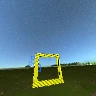
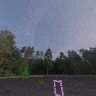
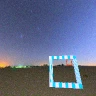
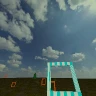
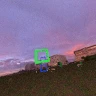
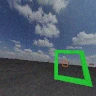
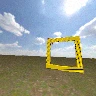
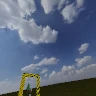
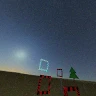
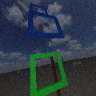
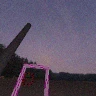
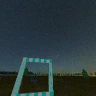
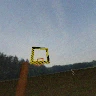
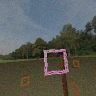
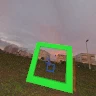
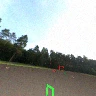
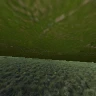
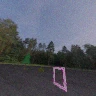
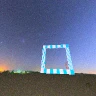
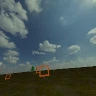
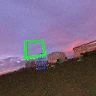
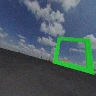
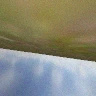
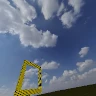
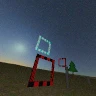
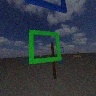
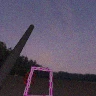
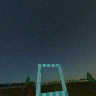
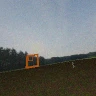
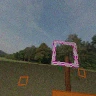
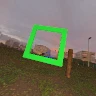
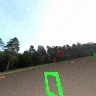

In [7]:
!curl -sLO https://raw.githubusercontent.com/AshishKumar4/dew/f56bbd29356b6458885693cbcc335654cf1166c0/tools/fpv_assets.py
!python fpv_assets.py fpv-assets

from dew.rl.flight import GateRace, Racing
from dew.rl.hyperlux import HyperLuxRenderer

racing = Racing()
race = GateRace(HyperLuxRenderer(16, "fpv-assets"), racing, views=("image", "passed"))
shown = [np.asarray(race.reset(0)["image"])]
for _ in range(60):
    stepped = race.step(jnp.zeros((16, 4)))
shown.append(np.asarray(stepped.observation["image"]))
figures.images(shown, columns=8, size=64, captions=["start", "after a second of hovering"])

A privileged PPO teacher learns the race from the drone's state, the next gates' corners and the
obstacles, flying 4096 drones at a time in JAX, without images. Here it trains for a few minutes on
the easiest courses, loops at a fifth of the full randomization, and is scored before and after on 256
drones of its own. `tools/fpv_race.py` runs the teacher at length, raising the difficulty as it stops
crashing, then pretrains DreamerV3 on its demonstrations from the camera alone and trains it online.

In [8]:
from dew.rl.env import Batched
from dew.rl.flight import TEACHER, FlightEnv

easy = Racing(families=(("loop", 1.0),))
teacher = ControlPPOObjective(ActorCritic(4, (256, 256, 256), (256, 256, 256, 256), spread=0.2), TEACHER,
                              discount=0.99, clip=0.2, entropy_cost=1e-4, reads=("teacher",))
flights = ControlRollout(teacher, Batched(FlightEnv(easy, ("teacher",), difficulty=0.2, ramp=0.2), 4096),
                         unroll_length=64, epochs=4, minibatches=32)
began = time.perf_counter()
taught = Trainer(teacher, optax.adam(3e-4), key=jax.random.key(12), rollout=flights).fit(idle, steps=12_800,
                                                                                          log_every=1280)
print(f"{time.perf_counter() - began:.0f} s of training")

judge = Batched(FlightEnv(easy, ("teacher", "passed"), difficulty=0.2, ramp=0.2), 256)
flown = jax.jit(lambda params, carry: env_rollout(judge, teacher.greedy, params, carry, easy.max_steps))
for name, params in (("fresh", teacher.init(jax.random.key(13))), ("trained", taught.variables)):
    _, steps = flown(params, start(judge, jax.random.key(14)))
    passed = np.asarray(steps.following.observation["passed"]).max(0)
    crashes = np.asarray(steps.following.terminated).sum(0)
    print(f"{name} teacher over {easy.episode_seconds:.0f} s: {passed.mean():.1f} gates in its best episode, "
          f"{crashes.mean():.1f} crashes a drone")

╭─  dew · ActorCritic  ───────────────────────────────────────────────────────────────────────────────────────────╮
│ 370,697 parameters  ·  on 1 × NVIDIA RTX PRO 6000 Blackwell Server Edition  ·  batch 1  ·  float32              │
│                                                                                                                 │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  12800/12800  100%  182.9 step/s  0:01:31 │
│                                                                                                                 │
│ train                                                                                                           │
│   loss                     0.4802  ▁▂▅▆▅██▄█▆       ↑ 142%                                                      │
│   entropy                  -4.829  █▇▆▅▃▃▃▂▂▁        ↓ 93%                                                      │
│   pg_clipfrac              0.1008  ▃▃▁▆▁▂█▅▁▇        ↑ 37%                                                      │
│   policy                 0.005677  ▂▂▃▆▅▃▃▁▄█       ↑ 446%                                                      │
│   ppo_kl                  0.01588  ▂▅▁▅▃▃█▃▂▆        ↑ 81%                                                      │
│   value                    0.4740  ▁▂▅▆▅██▄█▆       ↑ 138%                                                      │
│   data_wait_ms            0.01697  ▁▄▆▂▂▁▅█▃▇        ↑ 17%                                                      │
│   grad_norm                 6.874  ▂▁▃▆▇▇█▇▆▇       ↑ 399%                                                      │
│   pg_clipfrac_lower 0   flops 2.104e+10   compiles 1.000   cache_hits 1,710   cache_misses 1,108                │
│ peak_memory_gib 2.535                                                                                           │
│ throughput                                                                                                      │
│   step_time_ms              5.434  █▁▂▁▁▁▁▂▁▁        ↓ 49%                                                      │
│   samples_per_sec          23,556  ▁█▇████▇██        ↑ 97%                                                      │
│   mfu                        0.8%  ▁█▇████▇██     ↑ 0.4 pt                                                      │
│   hlo_flops_util             0.8%  ▁█▇████▇██     ↑ 0.4 pt                                                      │
│   hfu                        0.8%  ▁█▇████▇██     ↑ 0.4 pt                                                      │
│   rollout_seconds           5.375  █▁▁▁▁▁▁▁▁▂        ↓ 76%                                                      │
│ optimizer                                                                                                       │
│   accepted 100.0%                                                                                               │
│ rollout                                                                                                         │
│   episode_return            154.4  ▁▁▁▁▂▂▃▆██            ↑                                                      │
╰──────────────────────────────────────────────────────────────────────────────────────────────────  ✓ finished  ─╯

╭─  ✓ ActorCritic  ───────────────────────────╮
│    trained  12800 steps in 0:01:32          │
│ first step  after 16.38 s                   │
│       then  170.0 step/s                    │
│    goodput  82.1% of the wall time in steps │
│ final loss  0.4802                          │
╰─────────────────────────────────────────────╯

92 s of training


fresh teacher over 25 s: 0.0 gates in its best episode, 15.5 crashes a drone


trained teacher over 25 s: 14.3 gates in its best episode, 0.6 crashes a drone
